In [1]:

# ==========================================
# PROYECTO: CLASIFICACIÓN DE FRUTAS CON CNN
# Autor: Proyecto de clasificación de frutas
# ==========================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

# Comprobar el hardware disponible
gpu = tf.config.list_physical_devices("GPU")

if gpu:
    print("GPU disponible:", gpu)
else:
    print("Entrenaremos usando CPU.")

print("Entorno preparado correctamente.")


TensorFlow: 2.21.0
NumPy: 2.1.3
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Entorno preparado correctamente.


In [2]:

!pip install -q kagglehub


In [3]:

import kagglehub

# Descargar el dataset
ruta_dataset = kagglehub.dataset_download(
    "sriramr/fruits-fresh-and-rotten-for-classification"
)

print("Dataset descargado en:", ruta_dataset)


Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Dataset descargado en: /kaggle/input/fruits-fresh-and-rotten-for-classification


In [4]:

import os

for carpeta, subcarpetas, archivos in os.walk(ruta_dataset):
    nivel = carpeta.replace(ruta_dataset, "").count(os.sep)

    if nivel <= 2:
        print("  " * nivel + os.path.basename(carpeta) + "/")


fruits-fresh-and-rotten-for-classification/
  dataset/
    dataset/
    test/
    train/


In [5]:

import os

# Ruta que nos devolvió KaggleHub
print("Ruta del dataset:", ruta_dataset)

# Buscar las carpetas de entrenamiento y prueba
for raiz, carpetas, archivos in os.walk(ruta_dataset):
    nombre = os.path.basename(raiz).lower()

    if nombre in ["train", "test"]:
        print(f"\nConjunto encontrado: {nombre}")
        print("Ruta:", raiz)

        for clase in sorted(carpetas):
            ruta_clase = os.path.join(raiz, clase)

            imagenes = [
                f for f in os.listdir(ruta_clase)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            ]

            print(f"  {clase}: {len(imagenes)} imágenes")


Ruta del dataset: /kaggle/input/fruits-fresh-and-rotten-for-classification

Conjunto encontrado: test
Ruta: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/test
  freshapples: 395 imágenes
  freshbanana: 381 imágenes
  freshoranges: 388 imágenes
  rottenapples: 601 imágenes
  rottenbanana: 530 imágenes
  rottenoranges: 403 imágenes

Conjunto encontrado: train
Ruta: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/train
  freshapples: 1693 imágenes
  freshbanana: 1581 imágenes
  freshoranges: 1466 imágenes
  rottenapples: 2342 imágenes
  rottenbanana: 2224 imágenes
  rottenoranges: 1595 imágenes

Conjunto encontrado: test
Ruta: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test
  freshapples: 395 imágenes
  freshbanana: 381 imágenes
  freshoranges: 388 imágenes
  rottenapples: 601 imágenes
  rottenbanana: 530 imágenes
  rottenoranges: 403 imágenes

Conjunto encontrado: train
Ruta: /kaggle/input/fruits-fresh-and-rotten-f

Categorías: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


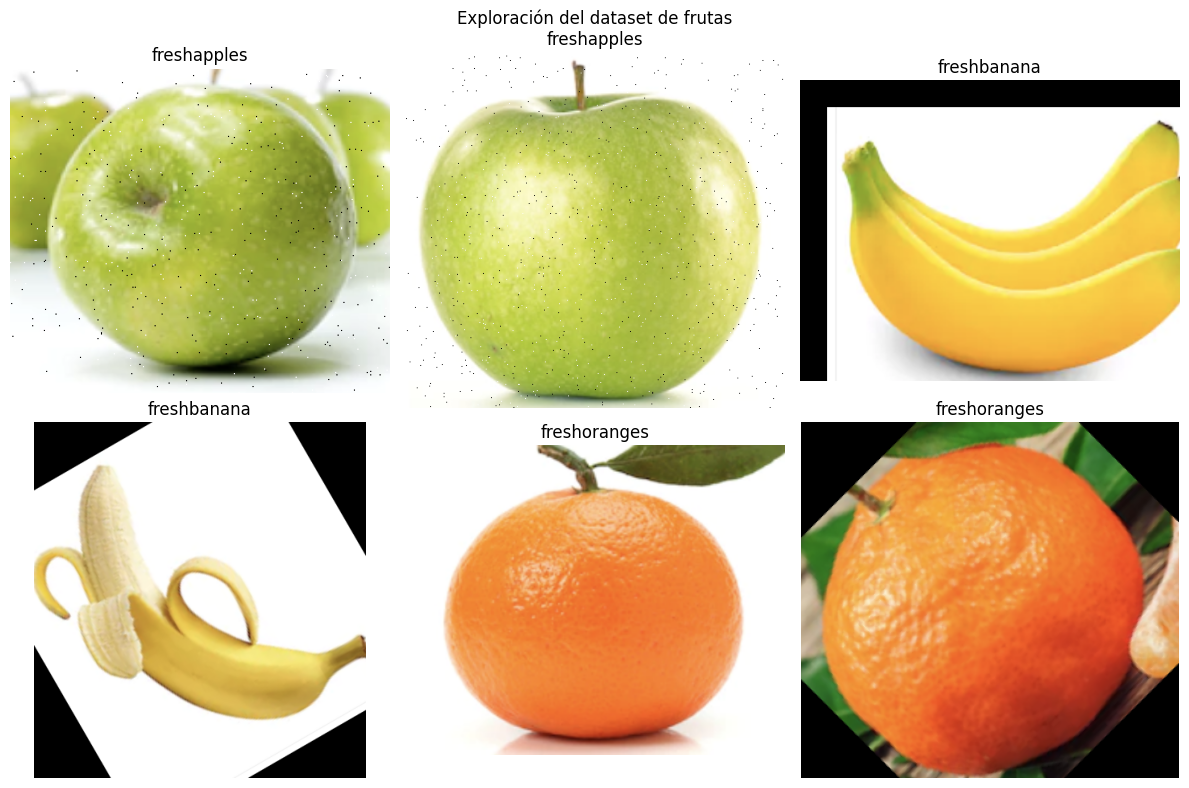

In [6]:

import matplotlib.pyplot as plt
from PIL import Image
import random

# Buscar la carpeta train automáticamente
ruta_train = None

for raiz, carpetas, archivos in os.walk(ruta_dataset):
    if os.path.basename(raiz).lower() == "train":
        ruta_train = raiz
        break

if ruta_train is None:
    raise FileNotFoundError("No se encontró la carpeta train.")

# Obtener las categorías
clases = [
    c for c in sorted(os.listdir(ruta_train))
    if os.path.isdir(os.path.join(ruta_train, c))
]

print("Categorías:", clases)

# Seleccionar hasta 2 imágenes de cada categoría
muestras = []

for clase in clases:
    ruta_clase = os.path.join(ruta_train, clase)

    imagenes = [
        os.path.join(ruta_clase, f)
        for f in os.listdir(ruta_clase)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    if imagenes:
        muestras.extend(
            (clase, ruta) for ruta in random.sample(
                imagenes, min(2, len(imagenes))
            )
        )

# Dibujar las imágenes
fig, ejes = plt.subplots(
    2, 3, figsize=(12, 8)
)

for eje, (clase, ruta) in zip(ejes.flat, muestras):
    imagen = Image.open(ruta).convert("RGB")
    eje.imshow(imagen)
    eje.set_title(clase)
    eje.axis("off")

for eje in ejes.flat[len(muestras):]:
    eje.axis("off")

plt.suptitle("Exploración del dataset de frutas")
plt.tight_layout()
plt.show()


In [7]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

ruta_test = None

for raiz, carpetas, archivos in os.walk(ruta_dataset):
    if os.path.basename(raiz).lower() == "test":
        ruta_test = raiz
        break

if ruta_test is None:
    raise FileNotFoundError("No se encontró la carpeta test.")

train_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_train,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_train,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_test,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Clases:", class_names)
print("Número de clases:", len(class_names))

Found 10901 files belonging to 6 classes.
Using 8721 files for training.
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.
Clases: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Número de clases: 6


In [8]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [9]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.10)
])


In [10]:
num_classes = len(class_names)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "modelo_frutas.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks
)

Epoch 1/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 91s 105ms/step - accuracy: 0.6730 - loss: 0.8838 - val_accuracy: 0.8606 - val_loss: 0.4211
Epoch 2/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 16s 59ms/step - accuracy: 0.8415 - loss: 0.4667 - val_accuracy: 0.8927 - val_loss: 0.3119
Epoch 3/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 16s 59ms/step - accuracy: 0.8575 - loss: 0.3974 - val_accuracy: 0.9069 - val_loss: 0.2356
Epoch 4/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 16s 59ms/step - accuracy: 0.8810 - loss: 0.3396 - val_accuracy: 0.9248 - val_loss: 0.1971
Epoch 5/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 16s 59ms/step - accuracy: 0.8959 - loss: 0.3048 - val_accuracy: 0.9289 - val_loss: 0.1804
Epoch 6/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 15s 57ms/step - accuracy: 0.8907 - loss: 0.3019 - val_accuracy: 0.8706 - val_loss: 0.3492
Epoch 7/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 16s 59ms/step - accuracy: 0.9060 - loss: 0.2644 - val_accuracy: 0.9468 - val_loss: 0.1700
Epoch 8/25
273/273 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.9125 - loss: 0.2495 -

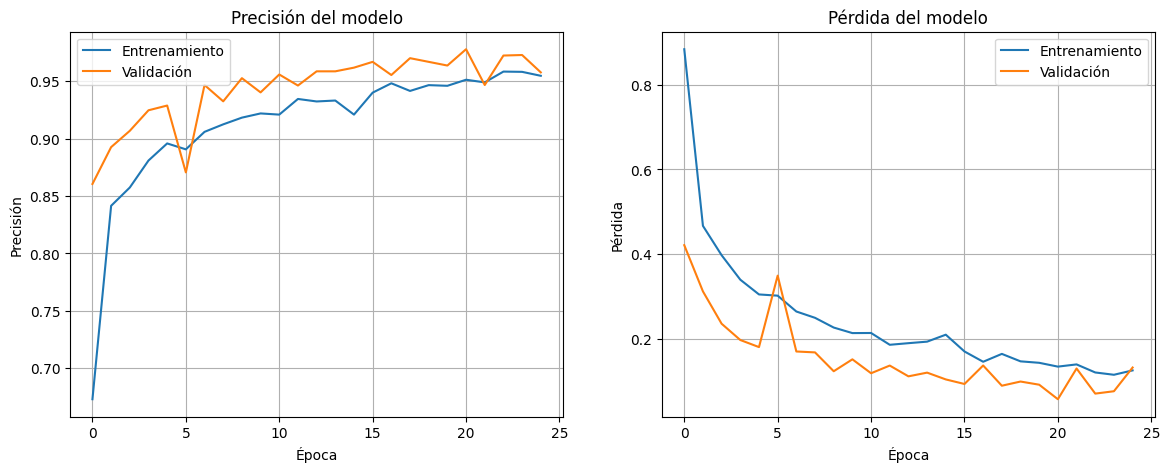

In [12]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")
plt.title("Precisión del modelo")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.title("Pérdida del modelo")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid()

plt.show()

In [13]:
modelo_entrenado = tf.keras.models.load_model("modelo_frutas.keras")

test_loss, test_accuracy = modelo_entrenado.evaluate(test_ds)

print(f"Pérdida en prueba: {test_loss:.4f}")
print(f"Precisión en prueba: {test_accuracy:.4f}")
print(f"Precisión en porcentaje: {test_accuracy * 100:.2f}%")

85/85 ━━━━━━━━━━━━━━━━━━━━ 17s 196ms/step - accuracy: 0.9774 - loss: 0.0651
Pérdida en prueba: 0.0651
Precisión en prueba: 0.9774
Precisión en porcentaje: 97.74%


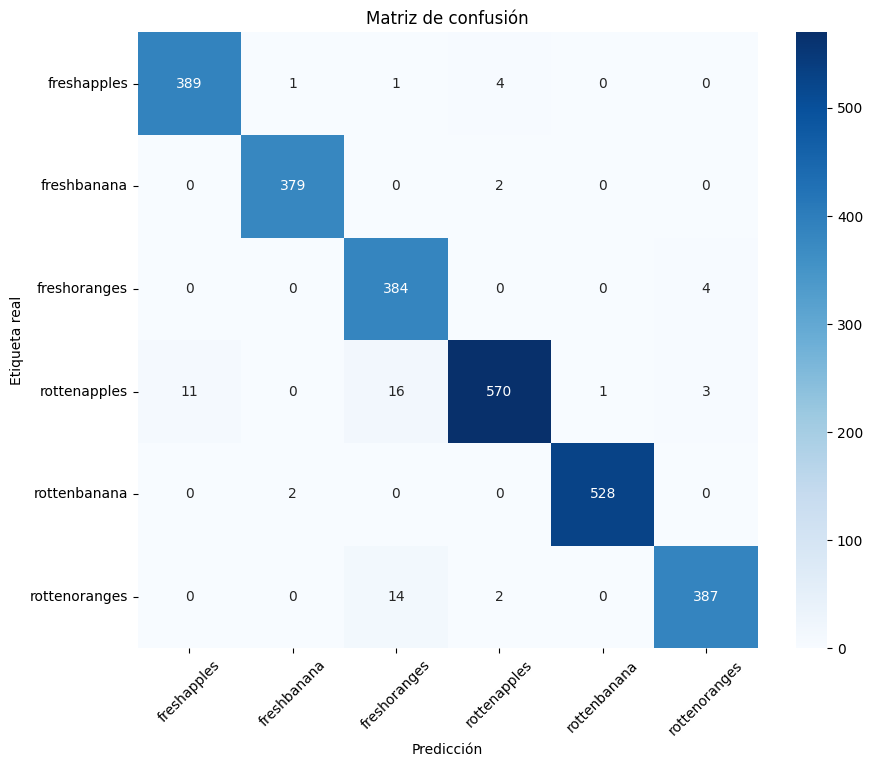

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []

for imagenes, etiquetas in test_ds:
    predicciones = modelo_entrenado.predict(imagenes, verbose=0)
    y_true.extend(etiquetas.numpy())
    y_pred.extend(np.argmax(predicciones, axis=1))

matriz = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [15]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

               precision    recall  f1-score   support

  freshapples       0.97      0.98      0.98       395
  freshbanana       0.99      0.99      0.99       381
 freshoranges       0.93      0.99      0.96       388
 rottenapples       0.99      0.95      0.97       601
 rottenbanana       1.00      1.00      1.00       530
rottenoranges       0.98      0.96      0.97       403

     accuracy                           0.98      2698
    macro avg       0.98      0.98      0.98      2698
 weighted avg       0.98      0.98      0.98      2698



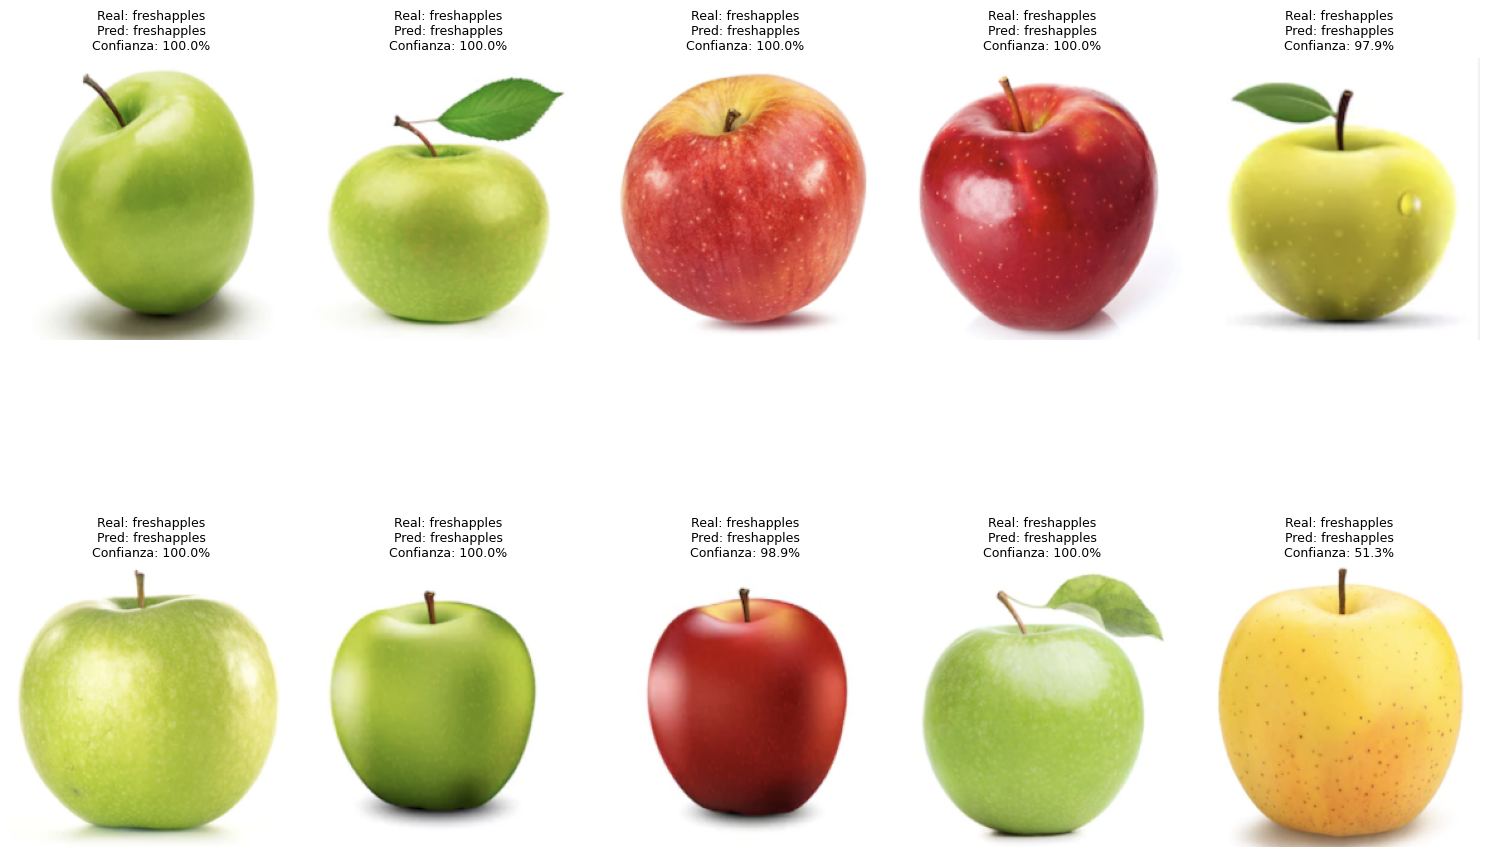

In [16]:
plt.figure(figsize=(15, 12))

imagenes_mostradas = 0

for imagenes, etiquetas in test_ds:
    predicciones = modelo_entrenado.predict(imagenes, verbose=0)
    clases_predichas = np.argmax(predicciones, axis=1)

    for i in range(len(imagenes)):
        if imagenes_mostradas >= 10:
            break

        plt.subplot(2, 5, imagenes_mostradas + 1)

        imagen = imagenes[i].numpy()
        etiqueta_real = class_names[etiquetas[i].numpy()]
        etiqueta_predicha = class_names[clases_predichas[i]]
        confianza = np.max(predicciones[i]) * 100

        plt.imshow(imagen)
        plt.title(
            f"Real: {etiqueta_real}\n"
            f"Pred: {etiqueta_predicha}\n"
            f"Confianza: {confianza:.1f}%",
            fontsize=9
        )
        plt.axis("off")

        imagenes_mostradas += 1

    if imagenes_mostradas >= 10:
        break

plt.tight_layout()
plt.show()


In [17]:
modelo_entrenado.save("modelo_frutas_final.keras")

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


In [18]:
from google.colab import files

files.download("modelo_frutas_final.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>